# 02 - Residual Mapping vs Baseline

**Goal**: Compare residual connection variants against vanilla baseline

**Baseline Reference** (from 01_baseline_reproduction.ipynb):
- Architecture: VanillaRNN (64 hidden, 1 layer)
- Loss: L1
- Validation MAE: 0.1616°
- Kaggle Score: 0.3937°
- Generalization Gap: 0.2321°

**Residual Variants to Test**:
1. **InputResidualRNN**: Skip connection from input to output
2. **HiddenResidualRNN**: Residual in hidden layers
3. **DeepResidualRNN**: Multi-layer with inter-layer residuals

**Hypothesis**: Residual connections improve generalization by:
- Allowing gradient flow for better optimization
- Preserving input information through skip connections
- Reducing overfitting via implicit regularization

**Experiment Design**:
- Same data loading (seed=42, val_ratio=0.2)
- Same training config (lr=0.001, batch=256, patience=15)
- Same loss function (L1)
- Only difference: architecture (baseline vs residual)

---

## 📦 Imports & Setup

In [1]:
import sys
sys.path.append('../../')

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Import models
from models.vanilla_rnn import VanillaRNN
from models.residual_rnn import InputResidualRNN, HiddenResidualRNN, DeepResidualRNN

# Import utilities
from utils.data_loadingV2 import load_data, load_test_data
from utils.band_mapping import load_band_mapping
from utils.reproducibility_utils import seed_everything

# Set reproducibility
seed_everything(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

✅ Using device: cuda


## 📊 Load Data (Same as Baseline)

In [2]:
# Load training and validation data (EXACT same setup as baseline)
train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path='../../datasets_challenge/train',
    val_ratio=0.2,
    sequence_length=20,
    target='sideSlip',
    threshold=True,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=256,
    scaling=True,
    seed=42,
    shuffle=True
)

input_dim = len(train_dataset.X_columns)

print(f"✅ Data loaded")
print(f"   Input dimension: {input_dim}")
print(f"   Training samples: {len(train_dataset):,}")
print(f"   Validation samples: {len(val_dataset):,}")

V5 Data Loader: Stratified Temporal Split

Processing 22 files...
Total groups after threshold: 42

Train: Many=90.0%, Medium=7.8%, Few=2.2%
Val:   Many=95.8%, Medium=2.8%, Few=1.3%

Train: 111,841 sequences | Val: 25,239 sequences

✅ Data loaded
   Input dimension: 22
   Training samples: 111,841
   Validation samples: 25,239


## 🏗️ Model Configurations

In [3]:
# Define all models to test
models_to_test = {
    'Baseline (VanillaRNN)': VanillaRNN(
        input_size=input_dim, 
        hidden_size=64, 
        num_layers=1
    ),
    'InputResidual': InputResidualRNN(
        input_size=input_dim, 
        hidden_size=64, 
        num_layers=1
    ),
    'HiddenResidual': HiddenResidualRNN(
        input_size=input_dim, 
        hidden_size=64, 
        num_layers=1
    ),
    'DeepResidual (2 layers)': DeepResidualRNN(
        input_size=input_dim, 
        hidden_size=64, 
        num_layers=2
    )
}

# Training configuration (SAME as baseline)
config = {
    'learning_rate': 0.001,
    'weight_decay': 1e-4,
    'batch_size': 256,
    'epochs': 100,
    'early_stopping_patience': 15,
    'loss_function': 'L1',
    'seed': 42
}

print("Models to test:")
for name, model in models_to_test.items():
    params = sum(p.numel() for p in model.parameters())
    print(f"  {name:30s}: {params:,} parameters")

Models to test:
  Baseline (VanillaRNN)         : 9,857 parameters
  InputResidual                 : 9,880 parameters
  HiddenResidual                : 11,329 parameters
  DeepResidual (2 layers)       : 18,177 parameters


## 🔧 Training Function

In [4]:
def train_model(model, model_name, train_loader, val_loader, config, device):
    """
    Train a model with the baseline configuration.
    Returns training history and best validation MAE.
    """
    model = model.to(device)
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config['learning_rate'],
        weight_decay=config['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        patience=10,
        factor=0.5
    )
    
    best_val_mae = float('inf')
    patience_counter = 0
    train_losses = []
    val_losses = []
    val_maes = []
    
    print(f"\n{'='*80}")
    print(f"Training: {model_name}")
    print(f"{'='*80}")
    
    for epoch in range(config['epochs']):
        # Training phase
        model.train()
        train_loss = 0.0
        
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).unsqueeze(1)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        avg_train_loss = train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        val_preds = []
        val_targets = []
        
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device).unsqueeze(1)
                
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                
                val_loss += loss.item()
                val_preds.append(outputs.cpu().numpy())
                val_targets.append(y_batch.cpu().numpy())
        
        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        
        val_preds = np.concatenate(val_preds)
        val_targets = np.concatenate(val_targets)
        val_mae = np.mean(np.abs(val_preds - val_targets))
        val_maes.append(val_mae)
        
        scheduler.step(val_mae)
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss: {avg_train_loss:.4f} | Val MAE: {val_mae:.4f}")
        
        # Early stopping
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            patience_counter = 0
            # Save best model
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= config['early_stopping_patience']:
                print(f"\n⏹️  Early stopping at epoch {epoch+1}")
                break
    
    print(f"\n✅ Best validation MAE: {best_val_mae:.4f}")
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    return {
        'model': model,
        'best_val_mae': best_val_mae,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'val_maes': val_maes
    }

print("✅ Training function ready")

✅ Training function ready


## 🏃 Train All Models

In [5]:
# Train all models
results = {}

for model_name, model in models_to_test.items():
    # Reset seed for each model for fair comparison
    seed_everything(42)
    
    result = train_model(model, model_name, train_loader, val_loader, config, device)
    results[model_name] = result

print("\n" + "="*80)
print("TRAINING COMPLETE")
print("="*80)


Training: Baseline (VanillaRNN)
Epoch   1 | Train Loss: 0.3092 | Val MAE: 0.2030
Epoch   5 | Train Loss: 0.1688 | Val MAE: 0.1738
Epoch  10 | Train Loss: 0.1530 | Val MAE: 0.1567
Epoch  15 | Train Loss: 0.1458 | Val MAE: 0.1735
Epoch  20 | Train Loss: 0.1392 | Val MAE: 0.1777
Epoch  25 | Train Loss: 0.1289 | Val MAE: 0.1665

⏹️  Early stopping at epoch 25

✅ Best validation MAE: 0.1567

Training: InputResidual
Epoch   1 | Train Loss: 0.3179 | Val MAE: 0.1862
Epoch   5 | Train Loss: 0.1629 | Val MAE: 0.1963
Epoch  10 | Train Loss: 0.1470 | Val MAE: 0.1608
Epoch  15 | Train Loss: 0.1394 | Val MAE: 0.1998
Epoch  20 | Train Loss: 0.1346 | Val MAE: 0.1882
Epoch  25 | Train Loss: 0.1233 | Val MAE: 0.1734

⏹️  Early stopping at epoch 25

✅ Best validation MAE: 0.1608

Training: HiddenResidual
Epoch   1 | Train Loss: 0.2888 | Val MAE: 0.1839
Epoch   5 | Train Loss: 0.1573 | Val MAE: 0.1736
Epoch  10 | Train Loss: 0.1405 | Val MAE: 0.1747
Epoch  15 | Train Loss: 0.1353 | Val MAE: 0.1541
Epoch 

## 📊 Results Comparison

In [6]:
# Create  results summary
summary_data = []
for model_name, result in results.items():
    model = result['model']
    params = sum(p.numel() for p in model.parameters())
    
    summary_data.append({
        'Model': model_name,
        'Val MAE': result['best_val_mae'],
        'Parameters': params,
        'Epochs Trained': len(result['val_maes'])
    })

summary_df = pd.DataFrame(summary_data).sort_values('Val MAE')

# Calculate improvement over baseline
baseline_mae = summary_df[summary_df['Model'].str.contains('Baseline')]['Val MAE'].values[0]
summary_df['Improvement (%)'] = ((baseline_mae - summary_df['Val MAE']) / baseline_mae * 100)

print("\n" + "="*80)
print("RESULTS SUMMARY")
print("="*80)
print(summary_df.to_string(index=False))
print("\n" + "="*80)


RESULTS SUMMARY
                  Model  Val MAE  Parameters  Epochs Trained  Improvement (%)
         HiddenResidual 0.154072       11329              30         1.703088
  Baseline (VanillaRNN) 0.156741        9857              25         0.000000
DeepResidual (2 layers) 0.159705       18177              65        -1.891038
          InputResidual 0.160833        9880              25        -2.610422



## 📈 Training Curves Comparison

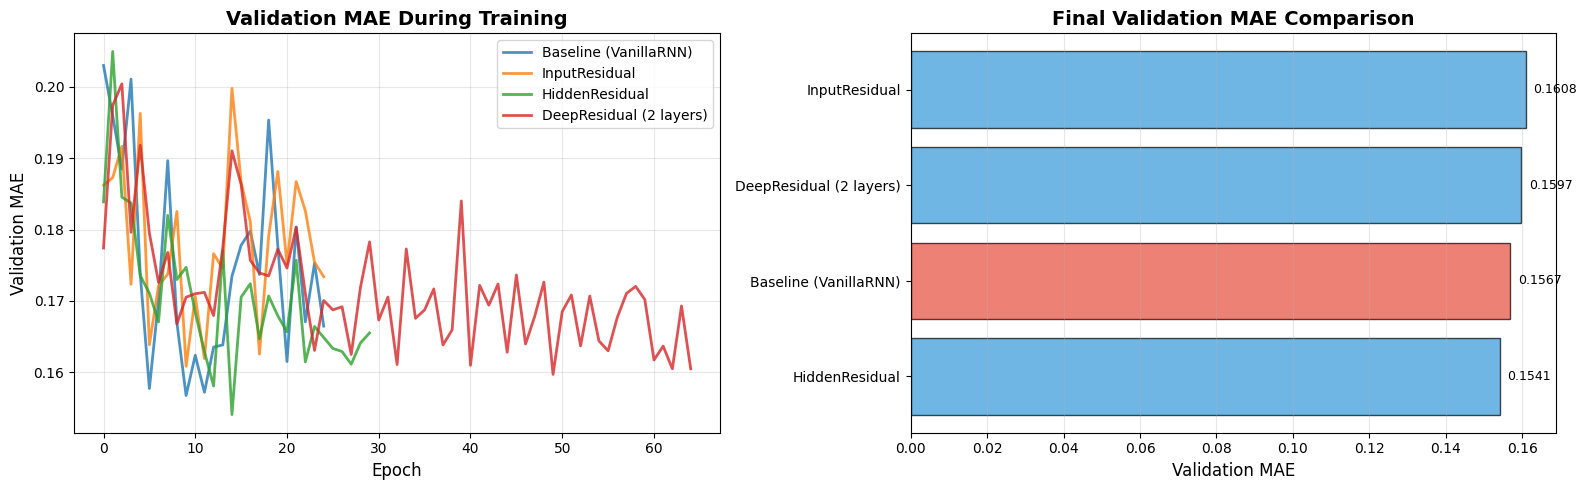

In [7]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Validation MAE over epochs
ax = axes[0]
for model_name, result in results.items():
    ax.plot(result['val_maes'], label=model_name, linewidth=2, alpha=0.8)

ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Validation MAE', fontsize=12)
ax.set_title('Validation MAE During Training', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Final validation MAE comparison
ax = axes[1]
models = summary_df['Model'].values
maes = summary_df['Val MAE'].values
colors = ['#e74c3c' if 'Baseline' in m else '#3498db' for m in models]

bars = ax.barh(range(len(models)), maes, color=colors, alpha=0.7, edgecolor='black')
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=10)
ax.set_xlabel('Validation MAE', fontsize=12)
ax.set_title('Final Validation MAE Comparison', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Add value labels
for i, (bar, mae) in enumerate(zip(bars, maes)):
    ax.text(mae + 0.002, i, f'{mae:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('residual_vs_baseline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 🎯 Generate Test Predictions (All Models)

In [8]:
print(f"\n{'='*80}")
print(f"GENERATING TEST PREDICTIONS FOR ALL MODELS")
print(f"{'='*80}\n")

# Load test data (once for all models)
columns_to_drop = ['sideSlip', 'vyCG', 'latitude', 'longitude', 'time']
test_loader = load_test_data(
    test_path='../../datasets_challenge/test',
    scaler=scaler,
    columns_to_drop=columns_to_drop,
    sequence_length=20,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=256,
    seed=42
)

# Create submissions directory
Path('submissions').mkdir(exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M")

submission_files = []

# Generate predictions for ALL models
for model_name, result in results.items():
    model = result['model']
    val_mae = result['best_val_mae']
    
    print(f"\n🔮 Generating predictions: {model_name}")
    print(f"   Val MAE: {val_mae:.4f}")
    
    # Generate predictions
    model.eval()
    predictions = []
    
    with torch.no_grad():
        for X_batch in tqdm(test_loader, desc=f"  {model_name}", leave=False):
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            predictions.append(outputs.cpu().numpy())
    
    predictions = np.concatenate(predictions).flatten()
    
    # Create submission
    submission = pd.DataFrame({
        'id': range(len(predictions)),
        'predicted_sideslip': predictions
    })
    
    filename = f"submissions/submission_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}_val{val_mae:.4f}_{timestamp}.csv"
    submission.to_csv(filename, index=False)
    submission_files.append(filename)
    
    print(f"   ✅ Saved: {filename}")
    print(f"   Predictions: {len(predictions):,}, Mean: {predictions.mean():.4f}°, Std: {predictions.std():.4f}°")

print(f"\n{'='*80}")
print(f"✅ ALL SUBMISSIONS GENERATED: {len(submission_files)} files")
print(f"{'='*80}")


GENERATING TEST PREDICTIONS FOR ALL MODELS

📂 Loading Test Data (V1-Compatible)

Found 11 test files
🔧 Applying threshold per file: vxCG > 3.0 (grouping)

   test_part_001.csv         | 4 groups, 1,428 samples
   test_part_002.csv         | 1 groups, 10,190 samples
   test_part_003.csv         | No valid groups
   test_part_004.csv         | 2 groups, 6,914 samples
   test_part_005.csv         | 1 groups, 11,260 samples
   test_part_006.csv         | 1 groups, 10,256 samples
   test_part_007.csv         | 2 groups, 389 samples
   test_part_008.csv         | 2 groups, 3,177 samples
   test_part_009.csv         | 1 groups, 1,595 samples
   test_part_010.csv         | 1 groups, 3,168 samples
   test_part_011.csv         | 1 groups, 1,271 samples

✅ Total groups: 16

📊 Test Data Summary:
   Raw samples: 68,806
   After threshold: 49,648 (removed 19,158)
   Expected sequences: 49,628 (Kaggle expects 49,328)

✅ Test sequences: 49,328
   ✅ Count matches Kaggle requirement!


🔮 Generating pre

   ✅ Saved: submissions/submission_Baseline_VanillaRNN_val0.1567_20260208_2238.csv
   Predictions: 49,328, Mean: 0.0469°, Std: 1.4443°

🔮 Generating predictions: InputResidual
   Val MAE: 0.1608


   ✅ Saved: submissions/submission_InputResidual_val0.1608_20260208_2238.csv
   Predictions: 49,328, Mean: -0.0096°, Std: 1.4583°

🔮 Generating predictions: HiddenResidual
   Val MAE: 0.1541


   ✅ Saved: submissions/submission_HiddenResidual_val0.1541_20260208_2238.csv
   Predictions: 49,328, Mean: 0.0136°, Std: 1.4767°

🔮 Generating predictions: DeepResidual (2 layers)
   Val MAE: 0.1597


   ✅ Saved: submissions/submission_DeepResidual_2_layers_val0.1597_20260208_2238.csv
   Predictions: 49,328, Mean: 0.0399°, Std: 1.4600°

✅ ALL SUBMISSIONS GENERATED: 4 files


## 📝 Final Summary

In [9]:
print("\n" + "="*80)
print("RESIDUAL MAPPING EXPERIMENT SUMMARY")
print("="*80)

print("\n📊 Validation Results:")
print(summary_df.to_string(index=False))

print("\n🏆 Best Model:")
best_model_name = summary_df.iloc[0]['Model']
best_val_mae = summary_df.iloc[0]['Val MAE']
print(f"   Architecture: {best_model_name}")
print(f"   Val MAE: {best_val_mae:.4f}°")
print(f"   Improvement over baseline: {summary_df.iloc[0]['Improvement (%)']:.2f}%")

print("\n📈 Key Findings:")
if summary_df.iloc[0]['Improvement (%)'] > 1:
    print("   ✅ Residual connections improve validation performance")
elif summary_df.iloc[0]['Improvement (%)'] > 0:
    print("   ⚠️  Minor improvement - residual connections provide marginal benefit")
else:
    print("   ❌ No improvement - vanilla architecture performs best")

print("\n📁 Submissions Generated:")
for i, row in summary_df.iterrows():
    print(f"   {row['Model']:30s}: Val MAE {row['Val MAE']:.4f}°")

print("\n🎯 Next Steps:")
print("   1. Submit ALL models to Kaggle for comparison")
print("   2. Compare generalization gap (Kaggle - Val) for each architecture")
print("   3. Determine if residuals reduce overfitting vs baseline")
print(f"   4. Baseline reference: Val 0.1616°, Kaggle 0.3937° (gap: 0.2321°)")

print("\n" + "="*80)


RESIDUAL MAPPING EXPERIMENT SUMMARY

📊 Validation Results:
                  Model  Val MAE  Parameters  Epochs Trained  Improvement (%)
         HiddenResidual 0.154072       11329              30         1.703088
  Baseline (VanillaRNN) 0.156741        9857              25         0.000000
DeepResidual (2 layers) 0.159705       18177              65        -1.891038
          InputResidual 0.160833        9880              25        -2.610422

🏆 Best Model:
   Architecture: HiddenResidual
   Val MAE: 0.1541°
   Improvement over baseline: 1.70%

📈 Key Findings:
   ✅ Residual connections improve validation performance

📁 Submissions Generated:
   HiddenResidual                : Val MAE 0.1541°
   Baseline (VanillaRNN)         : Val MAE 0.1567°
   DeepResidual (2 layers)       : Val MAE 0.1597°
   InputResidual                 : Val MAE 0.1608°

🎯 Next Steps:
   1. Submit ALL models to Kaggle for comparison
   2. Compare generalization gap (Kaggle - Val) for each architecture
   3. Det